# DevEmotion — ResNeXt-50 ile Duygu Tanıma

Bu not defteri, **DevEmotion** ekip projesi kapsamında benim (Mert Ali Kızılkaya) bireysel katkım olan ResNeXt-50 mimarisiyle yapılan duygu tanıma deneylerini içerir. Ekibin tamamına ait proje için [DevEmotion ana reposuna](https://github.com/Efeyamann/Devemotion) bakabilirsiniz.

**Yaklaşım:** ImageNet üzerinde önceden eğitilmiş ResNeXt-50, FER-2013 veri setindeki 7 duygu sınıfına (angry, disgust, fear, happy, neutral, sad, surprise) göre fine-tune edilir. Ek olarak, tahmin edilen duyguya göre IMDB Top 1000 veri setinden film önerisi yapan basit bir modül eklenmiştir.

## 1. Kurulum, Veri Yükleme ve Ön İşleme

`archive.zip` (FER-2013) ve `imdb_top_1000.csv` dosyalarının not defteriyle aynı klasörde olması gerekir. Veri setleri boyut nedeniyle bu depoya dahil edilmemiştir — bkz. README.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, models, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import pandas as pd
import os
import time
import zipfile


if not os.path.exists('train') and os.path.exists('archive.zip'):
    print("📂 Arşiv çıkarılıyor... (Lütfen bekleyin)")
    with zipfile.ZipFile('archive.zip', 'r') as zip_ref:
        zip_ref.extractall('.')
    print("✅ Çıkarma işlemi tamam!")


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"🚀 Çalışılan Cihaz: {device}")


BATCH_SIZE = 32
LEARNING_RATE = 0.0001
EPOCHS = 10
NUM_CLASSES = 7
DATA_DIR = '.'
IMDB_PATH = 'imdb_top_1000.csv'

 
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.Grayscale(num_output_channels=3),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(15),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'test': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.Grayscale(num_output_channels=3),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

if os.path.exists(os.path.join(DATA_DIR, 'train')):
    image_datasets = {x: datasets.ImageFolder(os.path.join(DATA_DIR, x), data_transforms[x])
                      for x in ['train', 'test']}
    dataloaders = {x: DataLoader(image_datasets[x], batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
                   for x in ['train', 'test']}
    class_names = image_datasets['train'].classes
    dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'test']}
    print(f"Sınıflar: {class_names}")
    print(f"Eğitim Seti: {dataset_sizes['train']} | Test Seti: {dataset_sizes['test']}")
else:
    print("❌ HATA: Klasörler bulunamadı. Zip dosyası yüklü mü?")



## 2. Model Tanımı — ResNeXt-50 (Transfer Learning)

Son tam bağlantılı katman, 7 duygu sınıfına göre yeniden tanımlanır.

In [ ]:
# --- 3. MODEL: ResNeXt-50 ---

print("\n🔥 ResNeXt-50 Modeli Yükleniyor...")
model = models.resnext50_32x4d(weights=models.ResNeXt50_32X4D_Weights.IMAGENET1K_V1)

# Son katmanı 7 duygu sınıfına göre ayarlıyoruz
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, NUM_CLASSES)
model = model.to(device)



## 3. Eğitim Döngüsü (10 Epoch)

In [ ]:
# --- 4. EĞİTİM DÖNGÜSÜ ---
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

train_loss_hist = []
val_acc_hist = []

print(f"Eğitim Başlıyor... (Toplam {EPOCHS} Epoch)")
start_time = time.time()

for epoch in range(EPOCHS):
    epoch_start = time.time()

    # Train
    model.train()
    running_loss = 0.0
    for inputs, labels in dataloaders['train']:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * inputs.size(0)

    epoch_loss = running_loss / dataset_sizes['train']
    train_loss_hist.append(epoch_loss)

    # Validation
    model.eval()
    running_corrects = 0
    with torch.no_grad():
        for inputs, labels in dataloaders['test']:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            running_corrects += torch.sum(preds == labels.data)

    epoch_acc = running_corrects.double() / dataset_sizes['test']
    val_acc_hist.append(epoch_acc.item())

    epoch_end = time.time()
    duration = (epoch_end - epoch_start) / 60
    print(f'Epoch {epoch+1}/{EPOCHS} | Süre: {duration:.1f} dk | Loss: {epoch_loss:.4f} | Acc: {epoch_acc:.4f}')

total_time = time.time() - start_time
print(f"\n✅ ResNeXt Eğitimi Tamamlandı! Toplam Süre: {total_time/60:.1f} dakika")


torch.save(model.state_dict(), 'resnext50_duygu_modeli.pth')
print("✅ Model kaydedildi: resnext50_duygu_modeli.pth")


## 4. Test Seti Üzerinde Değerlendirme

Eğitim/doğrulama eğrileri, karmaşıklık matrisi ve sınıf başına ROC eğrisi (AUC skorlarıyla).

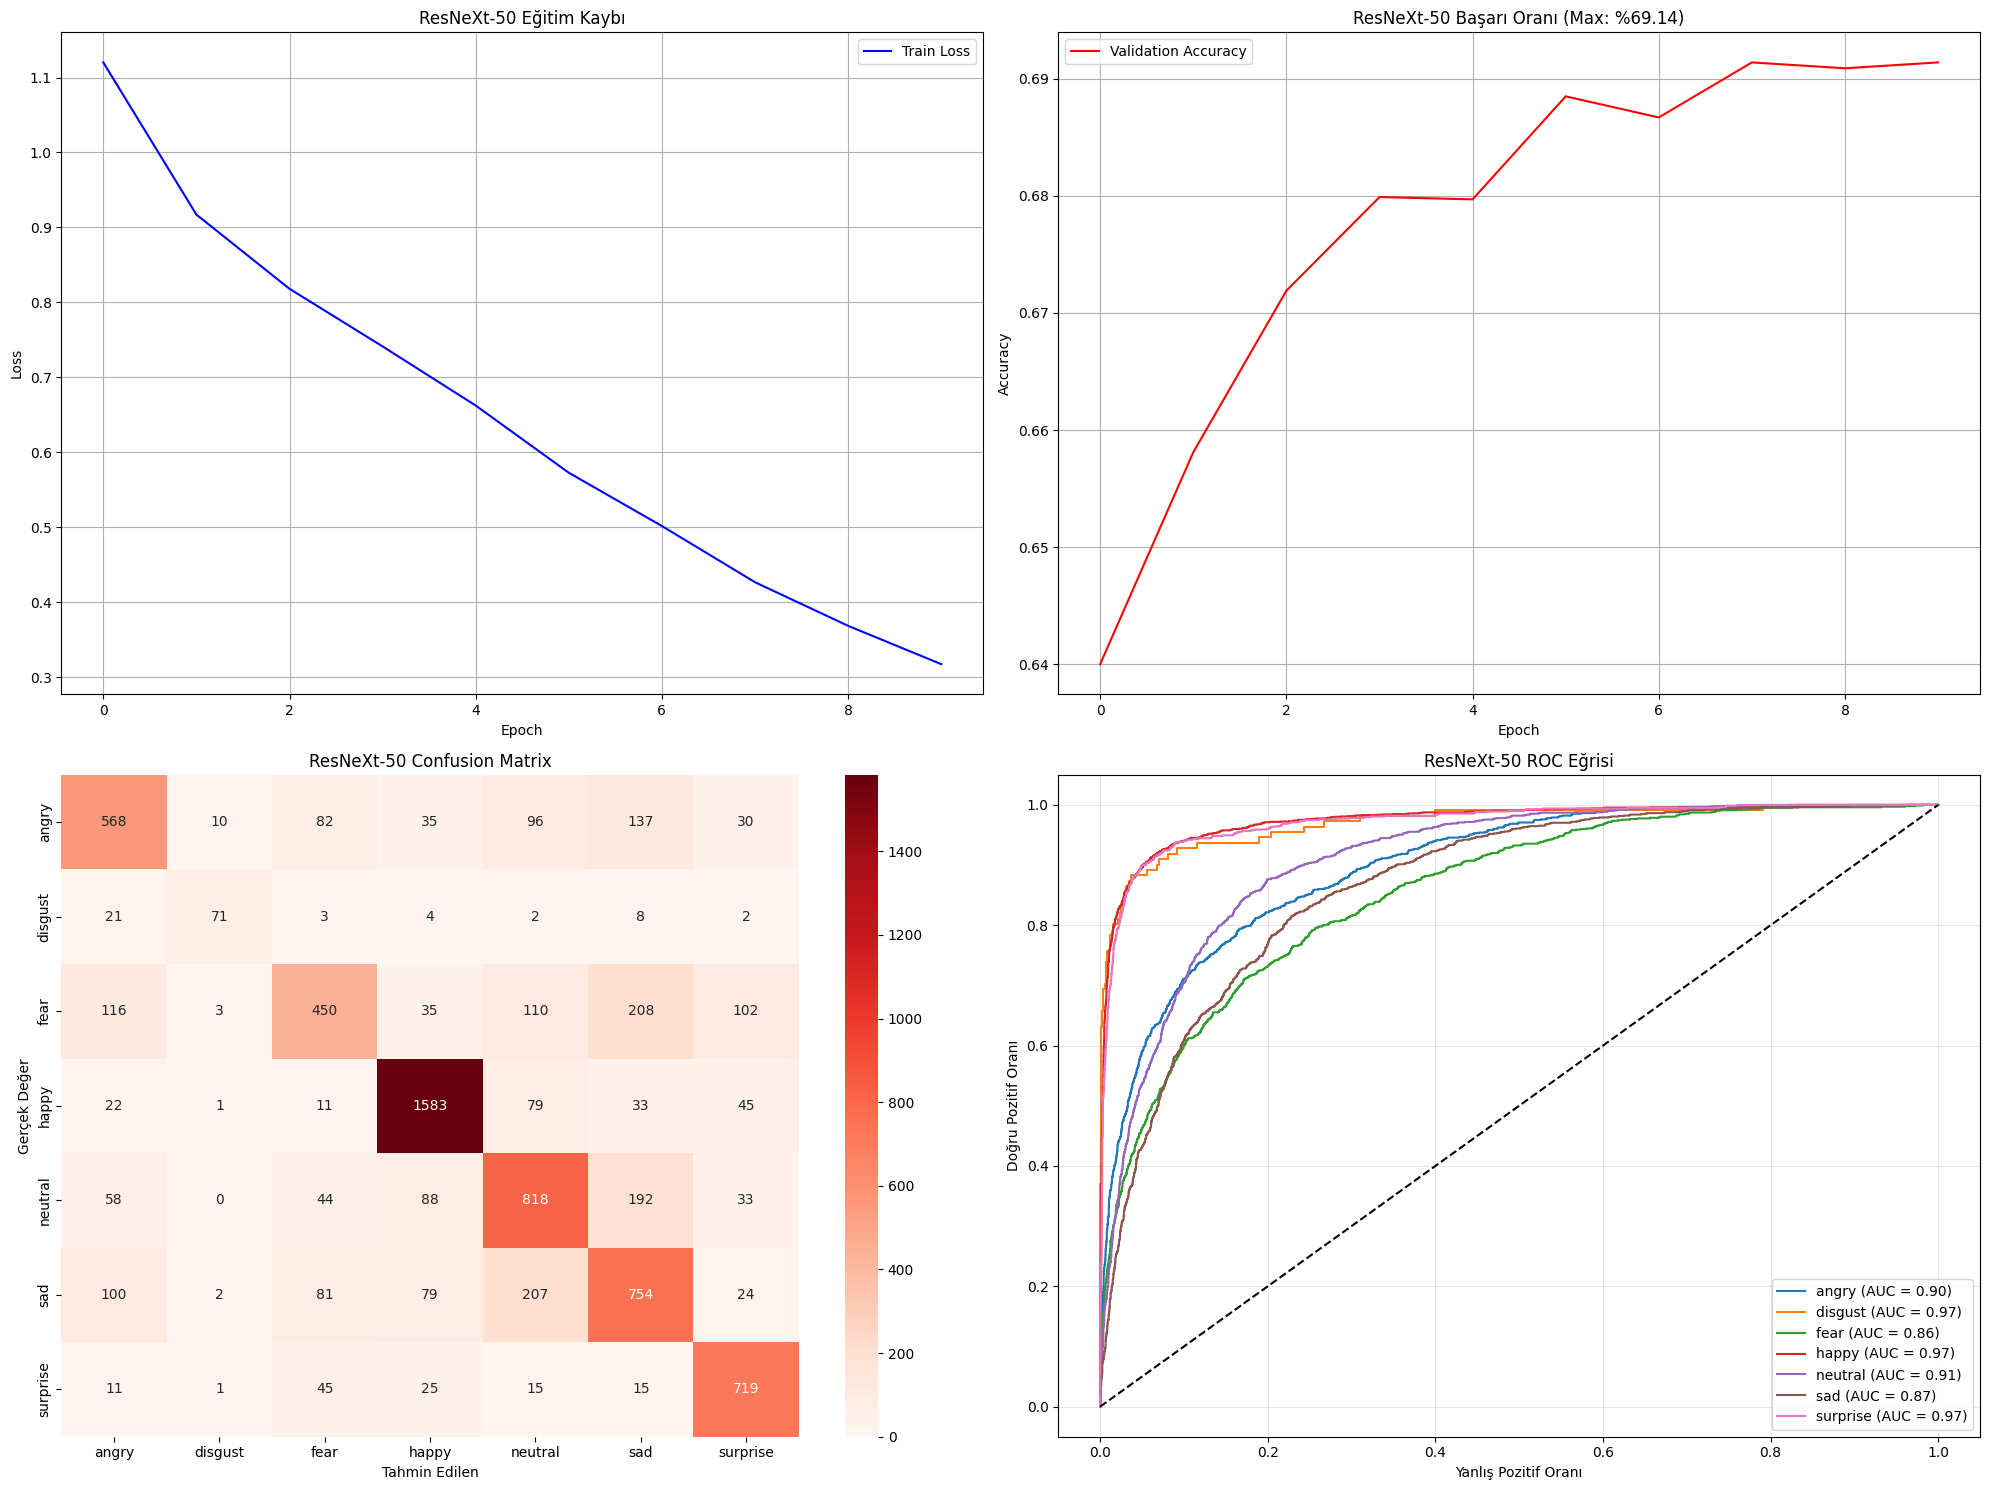

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize
import numpy as np


# (Bu değerler Bölüm 3'teki eğitim döngüsünden gelir: train_loss_hist, val_acc_hist)


plt.figure(figsize=(20, 15))


plt.subplot(2, 2, 1)
plt.plot(train_loss_hist, label='Train Loss', color='blue')
plt.title('ResNeXt-50 Eğitim Kaybı')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)


plt.subplot(2, 2, 2)
plt.plot(val_acc_hist, label='Validation Accuracy', color='red')
plt.title(f'ResNeXt-50 Başarı Oranı (Max: %{max(val_acc_hist)*100:.2f})')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

all_preds = []
all_labels = []
model.eval()
with torch.no_grad():
    for inputs, labels in dataloaders['test']:
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

cm = confusion_matrix(all_labels, all_preds)
plt.subplot(2, 2, 3)
sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names, cmap='Reds')
plt.xlabel('Tahmin Edilen')
plt.ylabel('Gerçek Değer')
plt.title('ResNeXt-50 Confusion Matrix')


y_test_bin = label_binarize(all_labels, classes=range(7))
all_probs = []
with torch.no_grad():
    for inputs, _ in dataloaders['test']:
        inputs = inputs.to(device)
        outputs = torch.softmax(model(inputs), dim=1)
        all_probs.extend(outputs.cpu().numpy())
all_probs = np.array(all_probs)

plt.subplot(2, 2, 4)
for i in range(7):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], all_probs[:, i])
    plt.plot(fpr, tpr, label=f'{class_names[i]} (AUC = {auc(fpr, tpr):.2f})')

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('Yanlış Pozitif Oranı')
plt.ylabel('Doğru Pozitif Oranı')
plt.title('ResNeXt-50 ROC Eğrisi')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Örnek Tahminler (Gerçek Etiket vs. Model Tahmini)

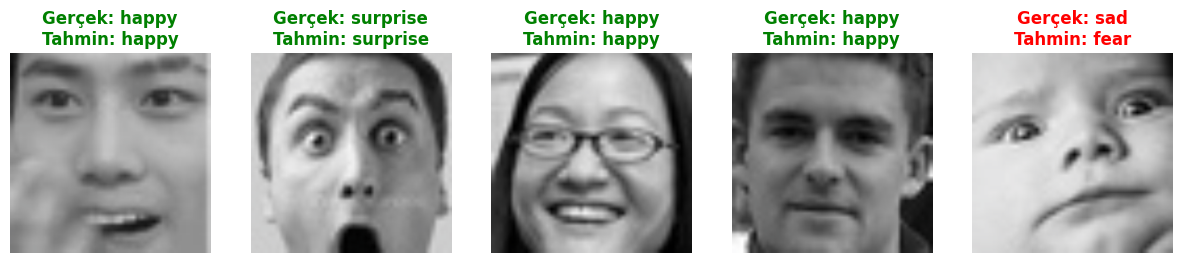

In [ ]:
def check_true_vs_pred(model, num_images=5):
    model.eval()
    images_so_far = 0
    plt.figure(figsize=(15, 10))

    with torch.no_grad():
        for i, (inputs, labels) in enumerate(dataloaders['test']):
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            for j in range(inputs.size()[0]):
                images_so_far += 1
                ax = plt.subplot(1, num_images, images_so_far)
                ax.axis('off')

                # Resmi gösterim için hazırla
                img = inputs.cpu().data[j].numpy().transpose((1, 2, 0))
                mean = np.array([0.485, 0.456, 0.406])
                std = np.array([0.229, 0.224, 0.225])
                img = std * img + mean
                img = np.clip(img, 0, 1)
                plt.imshow(img)

                true_label = class_names[labels[j]]
                pred_label = class_names[preds[j]]

                color = 'green' if true_label == pred_label else 'red'
                ax.set_title(f"Gerçek: {true_label}\nTahmin: {pred_label}", color=color, fontweight='bold')

                if images_so_far == num_images:
                    return

check_true_vs_pred(model)

## 6. Ek Özellik: Duyguya Göre Film Önerisi

Tahmin edilen duygu, önceden tanımlı bir duygu→tür eşlemesiyle IMDB Top 1000 veri setinde filtrelenerek 3 film önerisi sunar.

In [ ]:
def recommend_movies(emotion):
    genre_map = {
        'angry': 'Action', 'disgust': 'Horror', 'fear': 'Comedy',
        'happy': 'Romance', 'neutral': 'Sci-Fi', 'sad': 'Animation', 'surprise': 'Mystery'
    }
    target_genre = genre_map.get(emotion, 'Drama')

    if os.path.exists(IMDB_PATH):
        df = pd.read_csv(IMDB_PATH)
        filtered = df[df['Genre'].str.contains(target_genre, case=False, na=False)]
        if not filtered.empty:
            suggestions = filtered.sample(n=3)[['Series_Title', 'Genre', 'IMDB_Rating']]
            print(f"\n🎬 DUYGU: {emotion.upper()} -> TÜR: {target_genre}")
            for i, row in suggestions.iterrows():
                print(f"⭐ {row['Series_Title']} ({row['IMDB_Rating']})")
    else:
        print("IMDB dosyası bulunamadı!")


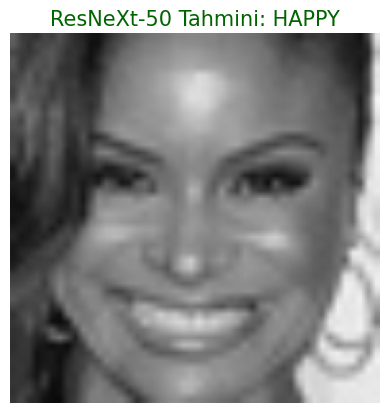


🎬 DUYGU: HAPPY -> TÜR: Romance
⭐ Bin-jip (8.0)
⭐ Hana-bi (7.8)
⭐ Cast Away (7.8)


In [ ]:
import numpy as np

model.eval()

try:
    
    test_loader_iter = iter(dataloaders['test'])
    images, labels = next(test_loader_iter)

    # İlk resmi seç ve modele gönder
    img = images[0].unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(img)
        _, pred = torch.max(output, 1)
        pred_emotion = class_names[pred.item()]

    
    img_display = images[0].permute(1, 2, 0).numpy()
    # Normalizasyonu geri al 
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img_display = std * img_display + mean
    img_display = np.clip(img_display, 0, 1)

    plt.imshow(img_display)
    plt.title(f"ResNeXt-50 Tahmini: {pred_emotion.upper()}", fontsize=15, color='darkgreen')
    plt.axis('off')
    plt.show()

    recommend_movies(pred_emotion)

except Exception as e:
    print(f"Öneri sırasında bir hata oluştu: {e}")